# Polynomial Regression

What if your data doesn't look linear at all? Let's look at some more realistic-looking page speed / purchase data:

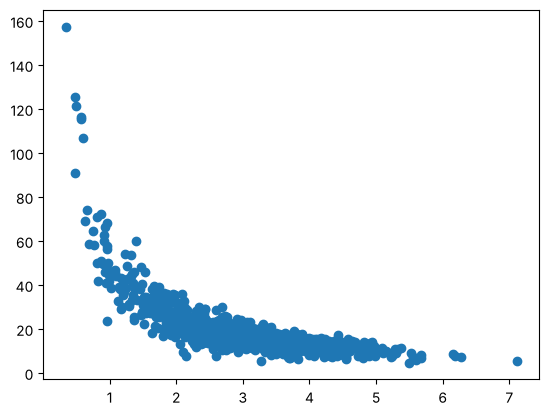

In [1]:
%matplotlib inline
from pylab import *
import numpy as np

#seed to generate the same random numbers on the different machines
np.random.seed(2)
pageSpeeds = np.random.normal(3.0, 1.0, 1000)
purchaseAmount = np.random.normal(50.0, 10.0, 1000) / pageSpeeds

scatter(pageSpeeds, purchaseAmount)

numpy has a handy polyfit function we can use, to let us construct an nth-degree polynomial model of our data that minimizes squared error. Let's try it with a 4th degree polynomial:

In [2]:
x = np.array(pageSpeeds)
y = np.array(purchaseAmount)

#Fit a polynomial of degree d=4 to points (x, y). Returns a vector of coefficients that minimises the squared error
p4 = np.poly1d(np.polyfit(x, y, 4))


We'll visualize our original scatter plot, together with a plot of our predicted values using the polynomial for page speed times ranging from 0-7 seconds:

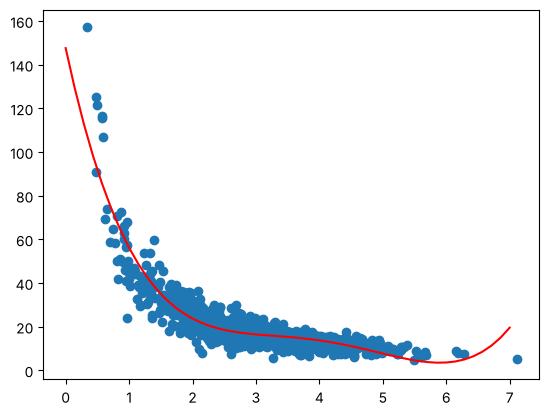

In [3]:
import matplotlib.pyplot as plt

# linspace returns evenly spaced numbers over a specified interval
xp = np.linspace(0, 7)
plt.scatter(x, y)
plt.plot(xp, p4(xp), c='r')
plt.show()

Measure the r-squared error :

In [4]:
from sklearn.metrics import r2_score

r2 = r2_score(y, p4(x))

print(r2)


0.8293766396303072


In [5]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Predict values
y_pred = p4(x)

# 2. Compute metrics
mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)

print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")

MAE  : 3.4847
MSE  : 28.0110
RMSE : 5.2925


## Activity

- Try different polynomial orders smaller and bigger than 4. Can you get a better fit with higher orders? What are your comments on the shape of the plot and the R-sqruared measure?

degré 1 -> R² = 0.5025
degré 2 -> R² = 0.6927
degré 3 -> R² = 0.7842
degré 4 -> R² = 0.8294
degré 6 -> R² = 0.8701
degré 8 -> R² = 0.8814
degré 10 -> R² = 0.8832
degré 15 -> R² = 0.8849


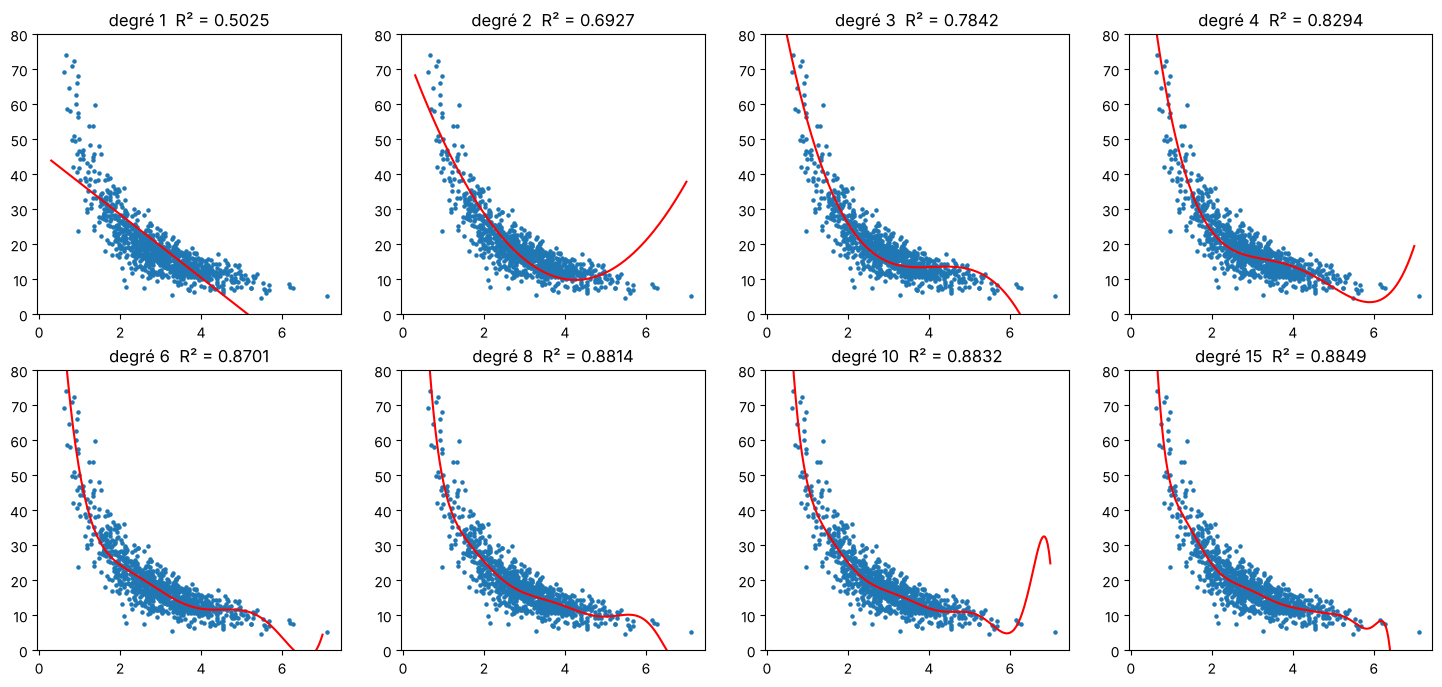

In [6]:
import warnings
warnings.filterwarnings('ignore')   # polyfit affiche des warnings pour les degrés élevés

xp = np.linspace(0.3, 7, 200)
degres = [1, 2, 3, 4, 6, 8, 10, 15]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, d in zip(axes.ravel(), degres):
    p = np.poly1d(np.polyfit(x, y, d))
    r2_d = r2_score(y, p(x))
    ax.scatter(x, y, s=5)
    ax.plot(xp, p(xp), c='r')
    ax.set_ylim(0, 80)
    ax.set_title("degré " + str(d) + "  R² = " + str(round(r2_d, 4)))
    print("degré", d, "-> R² =", round(r2_d, 4))
plt.show()

Le R² augmente avec le degré : 0.50 pour le degré 1, 0.69 pour 2, 0.78 pour 3, 0.83 pour 4, puis il se stabilise autour de 0.88 à partir du degré 8 (0.8832 pour 10 et 0.8849 pour 15). Donc on obtient un meilleur R² avec des degrés plus élevés, mais le gain devient très faible après le degré 6.

Sur les graphiques, les courbes de degré élevé (10 et 15) suivent les points de plus près mais elles commencent à osciller, surtout aux extrémités où il y a peu de données. Un R² qui augmente tout le temps ne veut donc pas dire que le modèle est meilleur : on risque le surapprentissage (overfitting).

- Write a **loop** that:

    1. Fits polynomial regression models for different degrees.  
    2. Computes the **RMSE** for each model using the training data.  
    3. Stores the results (degree and RMSE) in a list or table.  
    4. Prints or displays a **comparison table** showing which degree gives the lowest error.

In [7]:
resultats = []
for d in range(1, 16):
    p = np.poly1d(np.polyfit(x, y, d))
    y_pred = p(x)
    rmse_d = np.sqrt(mean_squared_error(y, y_pred))
    resultats.append((d, rmse_d))

import pandas as pd
tableau = pd.DataFrame(resultats, columns=['Degré', 'RMSE (train)'])
print(tableau.to_string(index=False))

meilleur = tableau.loc[tableau['RMSE (train)'].idxmin()]
print()
print("Degré avec le RMSE le plus faible :", int(meilleur['Degré']), "->", round(meilleur['RMSE (train)'], 4))

 Degré  RMSE (train)
     1      9.037407
     2      7.102226
     3      5.951615
     4      5.292538
     5      4.872437
     6      4.618424
     7      4.478315
     8      4.411788
     9      4.382166
    10      4.378589
    11      4.361979
    12      4.352000
    13      4.348547
    14      4.348544
    15      4.347856

Degré avec le RMSE le plus faible : 15 -> 4.3479


Le RMSE sur les données d'entraînement diminue à chaque fois qu'on augmente le degré, et le plus faible est obtenu pour le degré 15 (4.348). Mais la différence entre le degré 8 (4.41) et le degré 15 est minime, et ce résultat est logique : un polynôme de degré plus élevé contient les précédents, donc il ne peut pas faire pire sur les données d'entraînement. Cela ne prouve pas qu'il est le meilleur sur de nouvelles données.

- Plot the best-fitting polynomial curve to visually confirm your result.

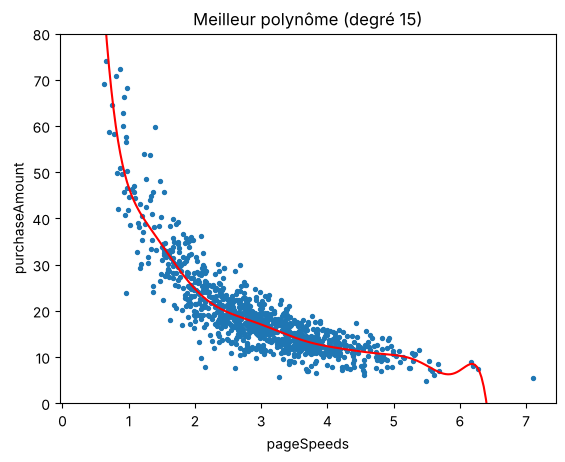

In [8]:
d_best = int(meilleur['Degré'])
p_best = np.poly1d(np.polyfit(x, y, d_best))

plt.scatter(x, y, s=8)
plt.plot(xp, p_best(xp), c='r')
plt.ylim(0, 80)
plt.xlabel('pageSpeeds')
plt.ylabel('purchaseAmount')
plt.title("Meilleur polynôme (degré " + str(d_best) + ")")
plt.show()

Le polynôme de plus haut degré passe bien au milieu du nuage de points, mais on voit qu'il est un peu plus tordu que celui de degré 4. Pour un vrai choix du degré il faudrait utiliser un jeu de test ou une validation croisée (voir Lab4 et Lab5), un degré entre 4 et 6 me semble un bon compromis ici.